In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# You are inside notebooks/, so project root is one level up
ROOT = Path("..").resolve()
DATA_PROCESSED = ROOT / "data" / "processed"
RESULTS = ROOT / "results"

plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.grid"] = True

print("DATA_PROCESSED:", DATA_PROCESSED)
print("Exists?", DATA_PROCESSED.exists())



DATA_PROCESSED: /Users/fut_payi/Desktop/F.I.T-Proteins/data/processed
Exists? True


## Dataset distribution and split

In [4]:
# Load labels
y_train = np.load(DATA_PROCESSED / "y_train_in.npy")
y_val   = np.load(DATA_PROCESSED / "y_val_ood.npy")
y_test  = np.load(DATA_PROCESSED / "y_test_ood.npy")

def split_stats(y):
    y = np.asarray(y).ravel()  # flatten in case it's (n, 1)
    n = int(len(y))
    n_pos = int(y.sum())
    pos_rate = n_pos / n if n > 0 else np.nan
    return n, n_pos, pos_rate

stats = {}
for name, y in [("train_in", y_train), ("val_ood", y_val), ("test_ood", y_test)]:
    stats[name] = split_stats(y)

df_splits = pd.DataFrame(stats, index=["n_total", "n_pos", "pos_rate"]).T
df_splits



,n_total,n_pos,pos_rate
train_in,34819.0,119.0,0.003418
val_ood,7268.0,30.0,0.004128
test_ood,7913.0,120.0,0.015165


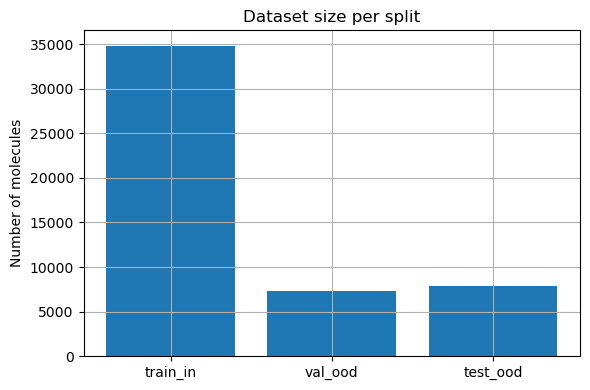

In [5]:
fig, ax = plt.subplots()
ax.bar(df_splits.index, df_splits["n_total"])
ax.set_ylabel("Number of molecules")
ax.set_title("Dataset size per split")
plt.tight_layout()
plt.show()


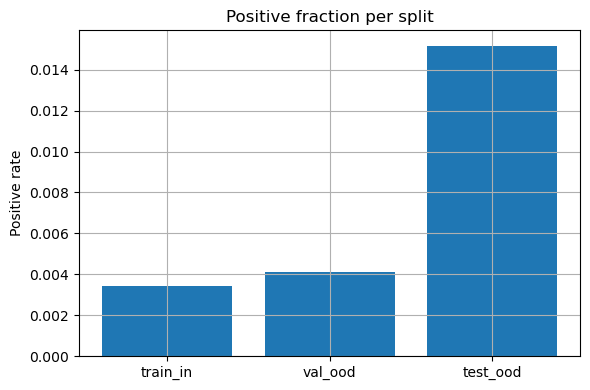

In [6]:
fig, ax = plt.subplots()
ax.bar(df_splits.index, df_splits["pos_rate"])
ax.set_ylabel("Positive rate")
ax.set_title("Positive fraction per split")
plt.tight_layout()
plt.show()


## Tree Models

In [7]:
rf_df  = pd.read_csv(RESULTS / "rf_ecfp"  / "rf_ecfp_experiments.csv")
xgb_df = pd.read_csv(RESULTS / "xgb_ecfp" / "xgb_ecfp_experiments.csv")

rf_df["model"] = "RF (ECFP)"
xgb_df["model"] = "XGB (ECFP)"

trees_df = pd.concat([rf_df, xgb_df], ignore_index=True)
trees_df.head()


,config_name,seed,n_estimators,max_features,max_depth,min_samples_leaf,oob_train_in,ap_val,auc_val,oob_train_all,...,used_early_stopping,learning_rate,subsample,colsample_bytree,min_child_weight,reg_lambda,reg_alpha,scale_pos_weight,ap_train,auc_train
0,rf_400_sqrt_leaf1,0,400.0,sqrt,NaN,1.0,0.997185,0.309597,0.925525,0.997077,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,rf_400_sqrt_leaf1,1,400.0,sqrt,NaN,1.0,0.997128,0.322241,0.925242,0.997006,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,rf_400_sqrt_leaf1,2,400.0,sqrt,NaN,1.0,0.997157,0.313407,0.945105,0.997077,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,rf_800_sqrt_leaf1,0,800.0,sqrt,NaN,1.0,0.997185,0.319541,0.932693,0.997101,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,rf_800_sqrt_leaf1,1,800.0,sqrt,NaN,1.0,0.996984,0.324831,0.944916,0.997077,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


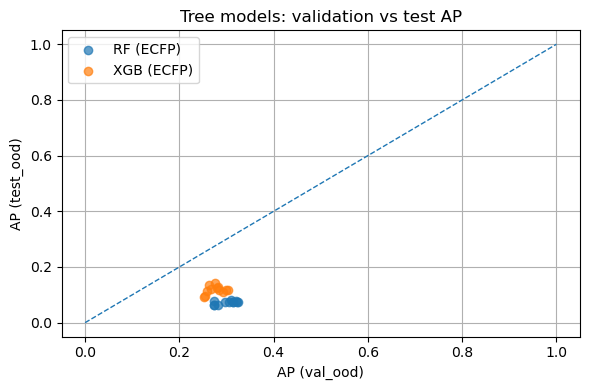

In [8]:
fig, ax = plt.subplots()

for model, group in trees_df.groupby("model"):
    ax.scatter(group["ap_val"], group["ap_test"], label=model, alpha=0.7)

ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
ax.set_xlabel("AP (val_ood)")
ax.set_ylabel("AP (test_ood)")
ax.set_title("Tree models: validation vs test AP")
ax.legend()
plt.tight_layout()
plt.show()


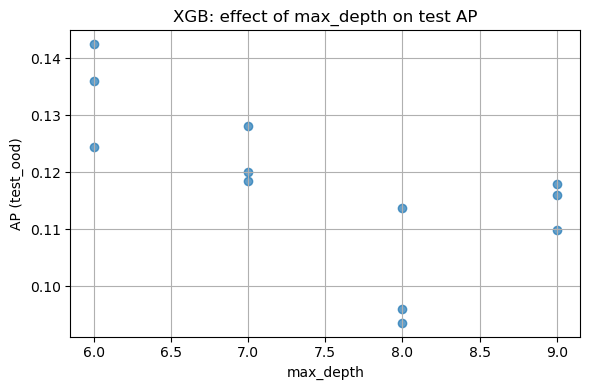

In [9]:
fig, ax = plt.subplots()
ax.scatter(xgb_df["max_depth"], xgb_df["ap_test"], alpha=0.7)
ax.set_xlabel("max_depth")
ax.set_ylabel("AP (test_ood)")
ax.set_title("XGB: effect of max_depth on test AP")
plt.tight_layout()
plt.show()


## CNNs and GNNs

In [11]:
def parse_nn_summary(path, model_name):
    vals = {}
    with open(path) as f:
        for line in f:
            if ":" not in line:
                continue
            key, value = line.strip().split(":", maxsplit=1)
            key = key.strip()
            value = value.strip()
            # crude numeric detection, but good enough for these files
            try:
                val_num = float(value)
                vals[key] = val_num
            except ValueError:
                vals[key] = value

    return {
        "model": model_name,
        "val_AP":      vals.get("Best val_AP", np.nan),
        "test_AP":     vals.get("Test_AP", np.nan),
        "test_ROC_AUC": vals.get("Test_ROC_AUC", np.nan),
    }

cnn_row = parse_nn_summary(RESULTS / "cnn_results" / "summary.txt", "SMILES-CNN")
gnn_row = parse_nn_summary(RESULTS / "gnn_results" / "summary.txt", "GNN (PyG)")

cnn_row, gnn_row


({'model': 'SMILES-CNN',
  'val_AP': 0.394327,
  'test_AP': 0.329424,
  'test_ROC_AUC': 0.818159},
 {'model': 'GNN (PyG)',
  'val_AP': 0.179433,
  'test_AP': 0.095883,
  'test_ROC_AUC': 0.80477})

## Model Comparison

In [12]:
def pick_best_tree(df, model_name, metric="ap_val"):
    row = df.sort_values(metric, ascending=False).iloc[0]
    return {
        "model": model_name,
        "val_AP":      row["ap_val"],
        "test_AP":     row["ap_test"],
        "test_ROC_AUC": row["auc_test"],
    }

rf_best  = pick_best_tree(rf_df,  "RF (ECFP)")
xgb_best = pick_best_tree(xgb_df, "XGB (ECFP)")


In [13]:
rows = [rf_best, xgb_best, cnn_row, gnn_row]
summary_df = pd.DataFrame(rows).set_index("model")
summary_df


,val_AP,test_AP,test_ROC_AUC
model,,,
RF (ECFP),0.324831,0.075441,0.619461
XGB (ECFP),0.302489,0.117945,0.761034
SMILES-CNN,0.394327,0.329424,0.818159
GNN (PyG),0.179433,0.095883,0.804770


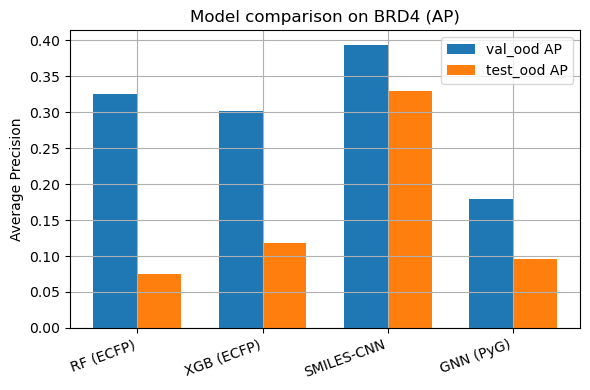

In [14]:
fig, ax = plt.subplots()
x = np.arange(len(summary_df))
width = 0.35

ax.bar(x - width/2, summary_df["val_AP"],  width, label="val_ood AP")
ax.bar(x + width/2, summary_df["test_AP"], width, label="test_ood AP")

ax.set_xticks(x)
ax.set_xticklabels(summary_df.index, rotation=20, ha="right")
ax.set_ylabel("Average Precision")
ax.set_title("Model comparison on BRD4 (AP)")
ax.legend()
plt.tight_layout()
plt.show()


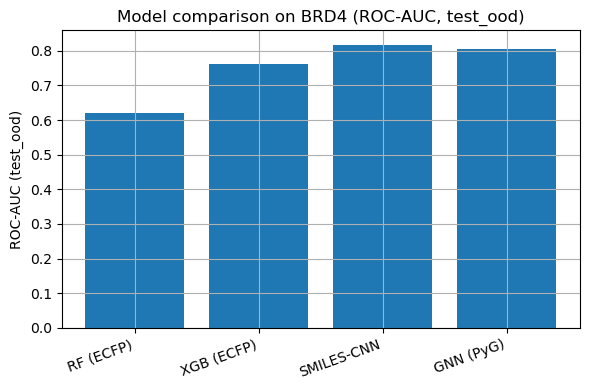

In [15]:
fig, ax = plt.subplots()
ax.bar(summary_df.index, summary_df["test_ROC_AUC"])
ax.set_ylabel("ROC-AUC (test_ood)")
ax.set_title("Model comparison on BRD4 (ROC-AUC, test_ood)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


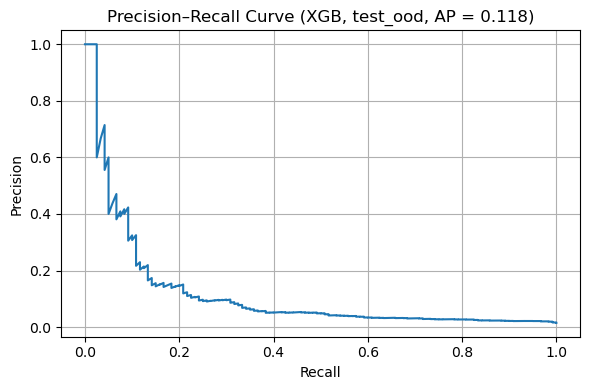

In [16]:
from scipy.sparse import load_npz
from sklearn.metrics import precision_recall_curve, average_precision_score
import xgboost as xgb

# Load ECFP features and labels
X_train = load_npz(DATA_PROCESSED / "X_train_in_ecfp.npz")
X_val   = load_npz(DATA_PROCESSED / "X_val_ood_ecfp.npz")
X_test  = load_npz(DATA_PROCESSED / "X_test_ood_ecfp.npz")

y_train = np.load(DATA_PROCESSED / "y_train_in.npy")
y_val   = np.load(DATA_PROCESSED / "y_val_ood.npy")
y_test  = np.load(DATA_PROCESSED / "y_test_ood.npy")

# 1) Pick best config from the CSV
best_row = xgb_df.sort_values("ap_val", ascending=False).iloc[0]

params = dict(
    objective="binary:logistic",
    tree_method="hist",
    n_estimators=int(best_row["n_estimators_final"]),
    learning_rate=float(best_row["learning_rate"]),
    max_depth=int(best_row["max_depth"]),
    subsample=float(best_row["subsample"]),
    colsample_bytree=float(best_row["colsample_bytree"]),
    min_child_weight=float(best_row["min_child_weight"]),
    reg_lambda=float(best_row["reg_lambda"]),
    reg_alpha=float(best_row["reg_alpha"]),
    scale_pos_weight=float(best_row["scale_pos_weight"]),
    eval_metric="aucpr",
    n_jobs=-1,
    random_state=int(best_row["seed"]),
)

# 2) Retrain on train_in + val_ood
X_all = xgb_ecfp = xgb  # to avoid name confusion in your head
X_all = load_npz(DATA_PROCESSED / "X_train_in_ecfp.npz")  # reassign cleanly
X_val2 = load_npz(DATA_PROCESSED / "X_val_ood_ecfp.npz")
from scipy.sparse import vstack
X_all = vstack([X_all, X_val2])
y_all = np.concatenate([y_train, y_val])

model = xgb.XGBClassifier(**params)
model.fit(X_all, y_all)

# 3) Predict on test_ood and draw PR curve
test_proba = model.predict_proba(X_test)[:, 1]
precision, recall, _ = precision_recall_curve(y_test, test_proba)
ap = average_precision_score(y_test, test_proba)

fig, ax = plt.subplots()
ax.plot(recall, precision)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title(f"Precision–Recall Curve (XGB, test_ood, AP = {ap:.3f})")
plt.tight_layout()
plt.show()
